# 06 - Fine-Tune & Evaluate

**Approach:** 5-fold Stratified Cross-Validation on merged train+val pool.  
**Models:** Logistic Regression, Decision Tree, XGBoost  
**Test set:** Touched exactly once for final evaluation.  

| Section | Content |
|---------|--------|
| 1 | Setup |
| 2 | Data loading & merge |
| 3 | CV strategy |
| 4 | Tune Logistic Regression (GridSearchCV + Pipeline) |
| 5 | Tune Decision Tree (GridSearchCV) |
| 6 | Tune XGBoost (Custom CV + early stopping) |
| 7 | Model selection comparison |
| 8 | Retrain on full pool |
| 9 | Test set evaluation |
| 10 | Ablation study |
| 11 | Error analysis |
| 12 | Calibration |
| 13 | Feature importance |
| 14 | Model Card |

## 6.1 Setup

In [2]:
# --- 1. Setup ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve,
    log_loss, make_scorer
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# Project utilities
import sys
sys.path.insert(0, "../src")
from utils import (
    save_fig, set_plot_style,
    SEED, FIG_DIR, DATA_DIR,
    OVERALL_RATING_COL, SUB_RATING_COLS, ALL_RATING_COLS
)

# Apply consistent styling
set_plot_style()
np.random.seed(SEED)

# Display options
pd.set_option('display.max_columns', 30)
warnings.filterwarnings('ignore', category=FutureWarning)

print('Setup complete.')

Setup complete.


## 6.2 Data Loading & Merge

In [3]:
# --- 2. Data Loading ---
df_train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
df_val   = pd.read_csv(os.path.join(DATA_DIR, 'val.csv'))
df_test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

topic_train = np.load(os.path.join(DATA_DIR, 'train_topic_features.npy'))
topic_val   = np.load(os.path.join(DATA_DIR, 'val_topic_features.npy'))
topic_test  = np.load(os.path.join(DATA_DIR, 'test_topic_features.npy'))

print(f'Train:  {df_train.shape}  Topics: {topic_train.shape}')
print(f'Val:    {df_val.shape}  Topics: {topic_val.shape}')
print(f'Test:   {df_test.shape}  Topics: {topic_test.shape}')

Train:  (440112, 27)  Topics: (440112, 117)
Val:    (94310, 27)  Topics: (94310, 117)
Test:   (94310, 27)  Topics: (94310, 117)


In [4]:
# --- 2.1 Merge Train + Val into Pool ---
df_pool = pd.concat([df_train, df_val], ignore_index=True)
topic_pool = np.concatenate([topic_train, topic_val], axis=0)

print(f'Pool:   {df_pool.shape}  Topics: {topic_pool.shape}')
print(f'Test:   {df_test.shape}  Topics: {topic_test.shape} (FROZEN)')

Pool:   (534422, 27)  Topics: (534422, 117)
Test:   (94310, 27)  Topics: (94310, 117) (FROZEN)


In [5]:
# --- 2.2 Feature Assembly ---
DROP_COLS = ['pros', 'cons', 'recommend_binary']

# Target
y_pool = df_pool['recommend_binary'].values
y_test = df_test['recommend_binary'].values

# Structured features
struct_pool = df_pool.drop(columns=DROP_COLS)
struct_test = df_test.drop(columns=DROP_COLS)

# Feature names
structured_feature_names = list(struct_pool.columns)
topic_feature_names = np.load(os.path.join(DATA_DIR, 'topic_feature_names.npy'), 
                              allow_pickle=True).tolist()
all_feature_names = structured_feature_names + topic_feature_names

# Concatenate structured + topic
X_pool = np.concatenate([struct_pool.values, topic_pool], axis=1)
X_test = np.concatenate([struct_test.values, topic_test], axis=1)

# Verify
print(f'Structured: {len(structured_feature_names)} | Topics: {len(topic_feature_names)} | Total: {len(all_feature_names)}')
print(f'X_pool: {X_pool.shape}  y_pool: {y_pool.shape}  (pos rate: {y_pool.mean():.3f})')
print(f'X_test: {X_test.shape}  y_test: {y_test.shape}  (pos rate: {y_test.mean():.3f})')
print(f'NaN check — pool: {np.isnan(X_pool).sum()}, test: {np.isnan(X_test).sum()}')

Structured: 24 | Topics: 117 | Total: 141
X_pool: (534422, 141)  y_pool: (534422,)  (pos rate: 0.604)
X_test: (94310, 141)  y_test: (94310,)  (pos rate: 0.604)
NaN check — pool: 0, test: 0


In [6]:
# --- Preprocessing ---
CONTINUOUS_COLS = ALL_RATING_COLS + ['firm_encoded'] + topic_feature_names
BINARY_COLS = [
    'is_current',
    'ceo_approv_Disapprove', 'ceo_approv_Mild', 'ceo_approv_No Opinion',
    'seniority_level_Management', 'seniority_level_Other',
    'seniority_level_Senior', 'seniority_level_Unknown',
    'review_year_2013', 'review_year_2014', 'review_year_2015',
    'review_year_2016', 'review_year_2017', 'review_year_2018',
    'review_year_2019', 'review_year_2020', 'review_year_2021',
]

# Verify all structured features accounted for
assert set(ALL_RATING_COLS + ['firm_encoded'] + BINARY_COLS) == set(structured_feature_names), \
    f"Missing: {set(structured_feature_names) - set(ALL_RATING_COLS + ['firm_encoded'] + BINARY_COLS)}"

# Feature names after ColumnTransformer: scaled first, then passthrough
scaled_feature_names = CONTINUOUS_COLS + BINARY_COLS

# DataFrame versions (needed for LR Pipeline with ColumnTransformer)
X_pool_df = pd.DataFrame(X_pool, columns=all_feature_names)
X_test_df = pd.DataFrame(X_test, columns=all_feature_names)

# Pre-scaled versions (for DT/XGBoost)
preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), CONTINUOUS_COLS),
    ('pass',  'passthrough',    BINARY_COLS)
])

X_pool_scaled = preprocessor.fit_transform(X_pool_df)
X_test_scaled = preprocessor.transform(X_test_df)

print(f'Scaled — Pool: {X_pool_scaled.shape}, Test: {X_test_scaled.shape}')
print(f'Continuous mean (first 3): {X_pool_scaled[:, :3].mean(axis=0).round(6)}')
print(f'Continuous std  (first 3): {X_pool_scaled[:, :3].std(axis=0).round(6)}')

Scaled — Pool: (534422, 141), Test: (94310, 141)
Continuous mean (first 3): [0. 0. 0.]
Continuous std  (first 3): [1. 1. 1.]


In [7]:
# Class Balance & Feature Groups
neg_count = (y_pool == 0).sum()
pos_count = (y_pool == 1).sum()
spw = neg_count / pos_count

print(f'Pool class balance: neg={neg_count:,} ({neg_count/len(y_pool):.1%}), pos={pos_count:,} ({pos_count/len(y_pool):.1%})')
print(f'scale_pos_weight = {spw:.4f}')

# Feature group indices (for ablation studies)
# Use .index() on scaled_feature_names to get correct positions after ColumnTransformer

overall_rating_idx = [scaled_feature_names.index(OVERALL_RATING_COL)]
sub_rating_idx = [scaled_feature_names.index(c) for c in SUB_RATING_COLS]
firm_idx = [scaled_feature_names.index('firm_encoded')]
topic_idx = [scaled_feature_names.index(c) for c in topic_feature_names]
ceo_idx = [scaled_feature_names.index(c) for c in scaled_feature_names if c.startswith('ceo_approv')]
structured_idx = [i for i in range(len(scaled_feature_names)) if i not in topic_idx]

print(f'\nFeature groups (indices in scaled space):')
print(f'  Overall rating: {overall_rating_idx}')
print(f'  Sub-ratings:    {sub_rating_idx} ({len(sub_rating_idx)} cols)')
print(f'  Firm encoded:   {firm_idx}')
print(f'  Topics:         {len(topic_idx)} cols')
print(f'  CEO approval:   {ceo_idx} ({len(ceo_idx)} cols)')
print(f'  Structured:     {len(structured_idx)} cols')

Pool class balance: neg=211,607 (39.6%), pos=322,815 (60.4%)
scale_pos_weight = 0.6555

Feature groups (indices in scaled space):
  Overall rating: [0]
  Sub-ratings:    [1, 2, 3, 4, 5] (5 cols)
  Firm encoded:   [6]
  Topics:         117 cols
  CEO approval:   [125, 126, 127] (3 cols)
  Structured:     24 cols


## 6.3 CV Strategy

Use 5-fold Stratified Cross-Validation on the merged pool (train + validation). 
Each fold preserves the 60/40 class ratio. This provides more robust performance 
estimates than a single train/val split and uses all available training data for both 
training and validation across folds.

Test set remains frozen until final evaluation in Section 9.

In [8]:
# --- 5-fold Stratified CV ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print('CV Strategy: 5-fold StratifiedKFold')
print(f'Primary metric: roc_auc | Secondary metric: f1')
print(f'Pool size: {len(y_pool):,} rows')
print()

# Verify fold sizes and class balance
for i, (train_idx, val_idx) in enumerate(cv.split(X_pool_scaled, y_pool)):
    train_pos = y_pool[train_idx].mean()
    val_pos   = y_pool[val_idx].mean()
    print(f'  Fold {i+1}: train={len(train_idx):,} (pos={train_pos:.3f}), '
          f'val={len(val_idx):,} (pos={val_pos:.3f})')

CV Strategy: 5-fold StratifiedKFold
Primary metric: roc_auc | Secondary metric: f1
Pool size: 534,422 rows

  Fold 1: train=427,537 (pos=0.604), val=106,885 (pos=0.604)
  Fold 2: train=427,537 (pos=0.604), val=106,885 (pos=0.604)
  Fold 3: train=427,538 (pos=0.604), val=106,884 (pos=0.604)
  Fold 4: train=427,538 (pos=0.604), val=106,884 (pos=0.604)
  Fold 5: train=427,538 (pos=0.604), val=106,884 (pos=0.604)


## 6.4 Logistic Regression (Validation of Exploration Config)

Exploration (Stage 4) showed LR performance is stable across regularisation 
settings (ΔAUC < 0.001). Rather than redundant grid search, we validate the 
selected config (C=0.01, L2 penalty) with 5-fold CV.

Pipeline wraps `ColumnTransformer` → `LogisticRegression` so the scaler refits 
on each fold's training split, preventing data leakage.

In [ ]:
# --- 4. Logistic Regression (Validation of Exploration Config) ---
# Exploration showed LR is insensitive to C; validate with CV

lr_preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), CONTINUOUS_COLS),
    ('pass',  'passthrough',    BINARY_COLS)
])

lr_pipe = Pipeline([
    ('preprocessor', lr_preprocessor),
    ('clf', LogisticRegression(C=0.01, class_weight='balanced', 
                                random_state=SEED, max_iter=1000))
])

t0 = time.time()
lr_cv_scores = cross_validate(
    lr_pipe, X_pool_df, y_pool, cv=cv,
    scoring={'auc': 'roc_auc', 'f1': 'f1'},
    return_train_score=True,
    n_jobs=2
)
lr_time = time.time() - t0

print(f'Done in {lr_time:.1f}s')
print(f'CV AUC: {lr_cv_scores["test_auc"].mean():.4f} (±{lr_cv_scores["test_auc"].std():.4f})')
print(f'CV F1:  {lr_cv_scores["test_f1"].mean():.4f} (±{lr_cv_scores["test_f1"].std():.4f})')

Done in 18.6s
CV AUC: 0.9080 (±0.0010)
CV F1:  0.8465 (±0.0008)


## 6.5 Decision Tree

Exploration identified max_depth=7 as optimal. Fine-tuning searches a focused 
grid around this value to validate with 5-fold CV and check if the merged pool 
shifts the optimum.

In [61]:
# Decission Tree
# Focus search around exploration optimum (max_depth=7)
dt_param_grid = {
    'max_depth': [5, 7, 10],           # 3 values around optimum
    'min_samples_leaf': [50, 100],     # 2 values
}
# 6 configs × 5 folds = 30 fits

t0 = time.time()
dt_search = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    dt_param_grid, cv=cv,
    scoring={'auc': 'roc_auc', 'f1': 'f1'},
    refit='auc', 
    return_train_score=True,
    n_jobs=1, verbose=1
)
dt_search.fit(X_pool_scaled, y_pool)
dt_time = time.time() - t0

print(f'\nDone in {dt_time:.1f}s')
print(f'Best AUC: {dt_search.best_score_:.4f}')
print(f'Best params: {dt_search.best_params_}')

Fitting 5 folds for each of 6 candidates, totalling 30 fits

Done in 1103.2s
Best AUC: 0.9157
Best params: {'max_depth': 10, 'min_samples_leaf': 100}


Saved: tune_dt_heatmap_v2.png


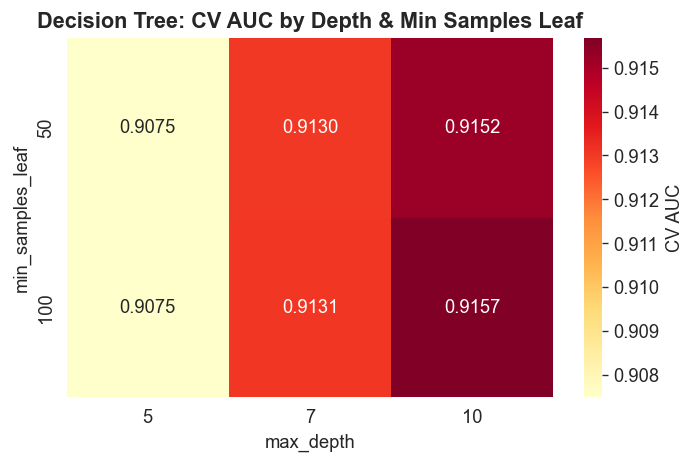

Best config: max_depth=10, min_samples_leaf=100
Best CV AUC: 0.9157


In [63]:
# --- Figure: DT Tuning Heatmap ---
dt_results = pd.DataFrame(dt_search.cv_results_)

pivot = dt_results.pivot_table(
    values='mean_test_auc',            # <-- fixed
    index='param_min_samples_leaf', 
    columns='param_max_depth'
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'CV AUC'})
ax.set_xlabel('max_depth')
ax.set_ylabel('min_samples_leaf')
ax.set_title('Decision Tree: CV AUC by Depth & Min Samples Leaf')
plt.tight_layout()
save_fig('tune_dt_heatmap')
plt.show()

print(f'Best config: max_depth={dt_search.best_params_["max_depth"]}, '
      f'min_samples_leaf={dt_search.best_params_["min_samples_leaf"]}')
print(f'Best CV AUC: {dt_search.best_score_:.4f}')

## 6.7 XGBoost (Focused Tuning with Early Stopping)

Exploration (Stage 4) identified max_depth=10 and learning_rate=0.1 as optimal 
(AUC=0.920). Fine-tuning fixes these values and searches regularization parameters 
not explored in Stage 4: `subsample`, `colsample_bytree`, and `min_child_weight`.

**Why custom CV loop:** `GridSearchCV` cannot pass a different `eval_set` per fold, 
which is required for per-fold early stopping. We run 5-fold CV manually, using 
each fold's validation split for early stopping.

**Parameters fixed from exploration:** `max_depth=10`, `learning_rate=0.1`  
**Parameters tuned:** `subsample`, `colsample_bytree`, `min_child_weight`  
**Early stopping:** `n_estimators=500` ceiling, patience=20 rounds

In [21]:
# --- 6. XGBoost Search Space ---
# Fix values from exploration, tune regularization params
FIXED_PARAMS = {
    'max_depth': 10,
    'learning_rate': 0.1,
}

xgb_param_grid = {
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5],
}

N_ESTIMATORS = 500   # Ceiling (early stopping will cut)
EARLY_STOP = 20      # Patience rounds

total_configs = 3 * 3 * 3  # 27
print(f'Fixed from exploration: max_depth={FIXED_PARAMS["max_depth"]}, '
      f'learning_rate={FIXED_PARAMS["learning_rate"]}')
print(f'Tuning grid: {total_configs} configs x 5 folds = {total_configs * 5} fits')
print(f'n_estimators ceiling: {N_ESTIMATORS}, early_stopping_rounds: {EARLY_STOP}')
print(f'scale_pos_weight: {spw:.4f}')

Fixed from exploration: max_depth=10, learning_rate=0.1
Tuning grid: 27 configs x 5 folds = 135 fits
n_estimators ceiling: 500, early_stopping_rounds: 20
scale_pos_weight: 0.6555


In [22]:
# --- 6. XGBoost Custom CV with Early Stopping ---
from itertools import product

# Generate all configs
param_names = list(xgb_param_grid.keys())
param_values = list(xgb_param_grid.values())
all_configs = [dict(zip(param_names, v)) for v in product(*param_values)]

xgb_cv_results = []
t0 = time.time()

for i, params in enumerate(all_configs):
    fold_aucs, fold_f1s, fold_iters = [], [], []
    fold_train_aucs = []
    
    for tr_idx, va_idx in cv.split(X_pool_scaled, y_pool):
        X_tr, X_va = X_pool_scaled[tr_idx], X_pool_scaled[va_idx]
        y_tr, y_va = y_pool[tr_idx], y_pool[va_idx]
        
        model = XGBClassifier(
            n_estimators=N_ESTIMATORS,
            early_stopping_rounds=EARLY_STOP,
            scale_pos_weight=spw,
            random_state=SEED,
            eval_metric='logloss',
            n_jobs=-1,
            **FIXED_PARAMS,
            **params
        )
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        
        y_va_prob = model.predict_proba(X_va)[:, 1]
        y_va_pred = model.predict(X_va)
        y_tr_prob = model.predict_proba(X_tr)[:, 1]
        
        fold_aucs.append(roc_auc_score(y_va, y_va_prob))
        fold_f1s.append(f1_score(y_va, y_va_pred))
        fold_iters.append(model.best_iteration + 1)
        fold_train_aucs.append(roc_auc_score(y_tr, y_tr_prob))
    
    result = {
        **FIXED_PARAMS,
        **params,
        'mean_auc': np.mean(fold_aucs),
        'std_auc': np.std(fold_aucs),
        'mean_f1': np.mean(fold_f1s),
        'mean_iterations': np.mean(fold_iters),
        'mean_train_auc': np.mean(fold_train_aucs),
        'overfit_gap': np.mean(fold_train_aucs) - np.mean(fold_aucs)
    }
    xgb_cv_results.append(result)
    
    if (i + 1) % 5 == 0 or (i + 1) == len(all_configs):
        elapsed = time.time() - t0
        print(f'  Config {i+1}/{len(all_configs)} done ({elapsed/60:.1f}min) '
              f'-- best so far: {max(r["mean_auc"] for r in xgb_cv_results):.4f}')

xgb_time = time.time() - t0
xgb_cv_df = pd.DataFrame(xgb_cv_results).sort_values('mean_auc', ascending=False)

print(f'\nDone in {xgb_time:.1f}s ({xgb_time/60:.1f} min)')
print(f'Best mean AUC: {xgb_cv_df.iloc[0]["mean_auc"]:.4f} ± {xgb_cv_df.iloc[0]["std_auc"]:.4f}')
print(f'Best params: subsample={xgb_cv_df.iloc[0]["subsample"]}, '
      f'colsample_bytree={xgb_cv_df.iloc[0]["colsample_bytree"]}, '
      f'min_child_weight={int(xgb_cv_df.iloc[0]["min_child_weight"])}')
print(f'Mean iterations (early stopped): {xgb_cv_df.iloc[0]["mean_iterations"]:.0f}')

    

  Config 5/27 done (11.0min) -- best so far: 0.9207
  Config 10/27 done (22.6min) -- best so far: 0.9207
  Config 15/27 done (33.0min) -- best so far: 0.9207
  Config 20/27 done (49.4min) -- best so far: 0.9207
  Config 25/27 done (67.8min) -- best so far: 0.9207
  Config 27/27 done (71.2min) -- best so far: 0.9207

Done in 4272.9s (71.2 min)
Best mean AUC: 0.9207 ± 0.0011
Best params: subsample=0.9, colsample_bytree=0.8, min_child_weight=5
Mean iterations (early stopped): 114


In [23]:
# --- XGBoost Top Configs ---
cols_show = ['subsample', 'colsample_bytree', 'min_child_weight', 
             'mean_auc', 'std_auc', 'mean_f1', 'mean_iterations', 'overfit_gap']
print('Top 10 configurations:')
print(xgb_cv_df[cols_show].head(10).round(4).to_string(index=False))

Top 10 configurations:
 subsample  colsample_bytree  min_child_weight  mean_auc  std_auc  mean_f1  mean_iterations  overfit_gap
       0.9               0.8                 5    0.9207   0.0011   0.8556            114.4       0.0201
       1.0               0.8                 5    0.9207   0.0010   0.8556            117.8       0.0207
       1.0               0.9                 5    0.9207   0.0009   0.8553            116.2       0.0204
       0.8               0.8                 3    0.9207   0.0010   0.8553             98.2       0.0197
       0.8               0.8                 5    0.9207   0.0010   0.8552            110.0       0.0194
       1.0               0.8                 3    0.9206   0.0010   0.8559            143.8       0.0252
       0.9               0.8                 3    0.9206   0.0011   0.8554            108.8       0.0215
       0.9               0.9                 3    0.9206   0.0010   0.8554            110.6       0.0216
       0.9               0.9    

Regularization tuning showed negligible impact (ΔAUC = 0.0004 across 27 configs). 
This confirms the model is not sensitive to these parameters given the already-optimal 
depth and learning rate from exploration. Best config selected for final model.

## 6.7 Model Selection Comparison

In [67]:
# --- Model Comparison Table ---
best_xgb_row = xgb_cv_df.iloc[0]

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'XGBoost'],
    'Mean CV AUC': [
        lr_cv_scores['test_auc'].mean(),
        dt_search.best_score_,
        best_xgb_row['mean_auc']
    ],
    'Std CV AUC': [
        lr_cv_scores['test_auc'].std(),
        dt_search.cv_results_['std_test_auc'][dt_search.best_index_],
        best_xgb_row['std_auc']
    ],
    'Mean CV F1': [
        lr_cv_scores['test_f1'].mean(),
        dt_search.cv_results_['mean_test_f1'][dt_search.best_index_],
        best_xgb_row['mean_f1']
    ]
})

print('=' * 80)
print('MODEL SELECTION COMPARISON')
print('=' * 80)
print(comparison.round(4).to_string(index=False))
print()
best_model = comparison.loc[comparison['Mean CV AUC'].idxmax(), 'Model']
print(f'Best model by CV AUC: {best_model}')


MODEL SELECTION COMPARISON
              Model  Mean CV AUC  Std CV AUC  Mean CV F1
Logistic Regression       0.9080      0.0010      0.8465
      Decision Tree       0.9157      0.0012      0.8478
            XGBoost       0.9207      0.0011      0.8556

Best model by CV AUC: XGBoost


In [68]:
# --- Overfitting Analysis ---
overfit_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'XGBoost'],
    'Train AUC': [
        lr_cv_scores['train_auc'].mean(),
        dt_search.cv_results_['mean_train_auc'][dt_search.best_index_],  # <-- fixed
        xgb_cv_df.iloc[0]['mean_train_auc']
    ],
    'Val AUC': [
        lr_cv_scores['test_auc'].mean(),
        dt_search.best_score_,
        xgb_cv_df.iloc[0]['mean_auc']
    ]
})
overfit_df['Overfit Gap'] = overfit_df['Train AUC'] - overfit_df['Val AUC']

print('Overfitting Analysis')
print('=' * 60)
print(overfit_df.round(4).to_string(index=False))

Overfitting Analysis
              Model  Train AUC  Val AUC  Overfit Gap
Logistic Regression     0.9082   0.9080       0.0002
      Decision Tree     0.9193   0.9157       0.0036
            XGBoost     0.9408   0.9207       0.0201


In [27]:
# Select LR for interpretability ---
FINAL_MODEL_NAME = 'Logistic Regression'

lr_auc = comparison.loc[comparison['Model'] == 'Logistic Regression', 'Mean CV AUC'].values[0]
xgb_auc = comparison.loc[comparison['Model'] == 'XGBoost', 'Mean CV AUC'].values[0]
auc_gap = xgb_auc - lr_auc

# Show AUC gap
print(f'XGBoost CV AUC:  {xgb_auc:.4f}')
print(f'LR CV AUC:       {lr_auc:.4f}')
print(f'AUC gap:         {auc_gap:.4f} ({auc_gap*100:.2f} pp)')


XGBoost CV AUC:  0.9207
LR CV AUC:       0.9080
AUC gap:         0.0127 (1.27 pp)


XGBoost achieves highest CV AUC (0.921), but Logistic Regression is selected as 
the final model. The research question asks which factors drive employee recommendations 
— LR coefficients (as odds ratios) directly answer this, while XGBoost feature 
importance is less interpretable. The AUC gap (~1.3%) represents minimal predictive 
cost for substantial interpretability gain.

## 6.8 Retrain on Full Pool

- **DT:** `GridSearchCV` with `refit=True` already retrained on full pool (`dt_search.best_estimator_`)
- **LR:** Retrain with fixed config (C=0.01) on full pool
- **XGBoost:** Retrain with best params; set `n_estimators` to mean early-stopped iterations from CV (no held-out set for early stopping)

In [ ]:
# --- 8. Retrain on Full Pool ---

# LR: Retrain 
lr_final = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('scale', StandardScaler(), CONTINUOUS_COLS),
        ('pass', 'passthrough', BINARY_COLS)
    ])),
    ('clf', LogisticRegression(C=0.01, class_weight='balanced', 
                                random_state=SEED, max_iter=1000))
])
lr_final.fit(X_pool_df, y_pool)

# DT: Already retrained via GridSearchCV
dt_final = dt_search.best_estimator_

# XGBoost: Retrain with early-stopped n_estimators
xgb_n_est = int(xgb_cv_df.iloc[0]['mean_iterations'])
xgb_final = XGBClassifier(
    n_estimators=xgb_n_est,
    scale_pos_weight=spw,
    random_state=SEED,
    eval_metric='logloss',
    n_jobs=-1,
    **FIXED_PARAMS,
    **{k: xgb_cv_df.iloc[0][k] for k in xgb_param_grid.keys()}
)
xgb_final.fit(X_pool_scaled, y_pool)

print('Models retrained on full pool:')
print(f'  LR:  C=0.01')
print(f'  DT:  {dt_search.best_params_}')
print(f'  XGB: n_estimators={xgb_n_est}, {FIXED_PARAMS}, '
      f'subsample={xgb_cv_df.iloc[0]["subsample"]}, '
      f'colsample_bytree={xgb_cv_df.iloc[0]["colsample_bytree"]}, '
      f'min_child_weight={int(xgb_cv_df.iloc[0]["min_child_weight"])}')

Models retrained on full pool:
  LR:  C=0.01
  DT:  {'max_depth': 10, 'min_samples_leaf': 100}
  XGB: n_estimators=114, {'max_depth': 10, 'learning_rate': 0.1}, subsample=0.9, colsample_bytree=0.8, min_child_weight=5


## 6.9 Ablation Experiments

Ablations measure each feature group's contribution by removing it and observing 
the performance drop. All experiments use Logistic Regression with the same 
hyperparameters (C=0.01) — only the feature set changes.

Ablations B, D, E, and F test the predictive power of **rating-based features** 
(sub-ratings, overall rating, CEO approval) which showed moderate-to-high target correlation 
in EDA.

Ablations C and G test whether **BERTopic features** add value beyond structured 
data, and whether they can sustain performance alone.

| Config | Features Removed | Tests |
|--------|------------------|-------|
| A | None (baseline) | Full model reference |
| B | Sub-ratings (5) | Sub-rating predictive power |
| C | Topics (117) | BERTopic value |
| D | CEO approval (3) | CEO approval predictive power |
| E | Overall rating (1) | Overall rating predictive power |
| F | Overall + CEO (4) | Combined rating features |
| G | All except topics | Topics alone |
| H | Sub-ratings + overall (6) | Model without numeric ratings |

In [34]:
# --- 9. Ablation Experiments ---
all_idx = list(range(X_pool_scaled.shape[1]))

ablation_configs = {
    'A: Full model':              all_idx,
    'B: No sub-ratings':          [i for i in all_idx if i not in sub_rating_idx],
    'C: No topics':               [i for i in all_idx if i not in topic_idx],
    'D: No ceo_approv':           [i for i in all_idx if i not in ceo_idx],
    'E: No overall_rating':       [i for i in all_idx if i not in overall_rating_idx],
    'F: No overall + ceo_approv': [i for i in all_idx if i not in overall_rating_idx + ceo_idx],
    'G: Topics only':             topic_idx,
    'H: No rating features':      [i for i in all_idx if i not in sub_rating_idx + overall_rating_idx],
}

# Run ablations using CV on pool
ablation_results = []

for name, idx in ablation_configs.items():
    X_ablation = X_pool_scaled[:, idx]
    
    scores = cross_validate(
        LogisticRegression(C=0.01, class_weight='balanced', 
                           random_state=SEED, max_iter=1000),
        X_ablation, y_pool, cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    
    ablation_results.append({
        'Config': name,
        'N Features': len(idx),
        'Mean CV AUC': scores['test_score'].mean(),
        'Std CV AUC': scores['test_score'].std()
    })
    print(f"{name:<25} AUC={scores['test_score'].mean():.4f} (n={len(idx)})")

# Results table
abl_df = pd.DataFrame(ablation_results)
baseline_auc = abl_df.loc[abl_df['Config'] == 'A: Full model', 'Mean CV AUC'].values[0]
abl_df['Δ AUC'] = abl_df['Mean CV AUC'] - baseline_auc

print('\n' + '=' * 60)
print('ABLATION RESULTS')
print('=' * 60)
print(abl_df.round(4).to_string(index=False))

A: Full model             AUC=0.9080 (n=141)
B: No sub-ratings         AUC=0.9001 (n=136)
C: No topics              AUC=0.9075 (n=24)
D: No ceo_approv          AUC=0.8595 (n=138)
E: No overall_rating      AUC=0.8964 (n=140)
F: No overall + ceo_approv AUC=0.8471 (n=137)
G: Topics only            AUC=0.6403 (n=117)
H: No rating features     AUC=0.8184 (n=135)

ABLATION RESULTS
                    Config  N Features  Mean CV AUC  Std CV AUC   Δ AUC
             A: Full model         141       0.9080      0.0010  0.0000
         B: No sub-ratings         136       0.9001      0.0011 -0.0079
              C: No topics          24       0.9075      0.0009 -0.0005
          D: No ceo_approv         138       0.8595      0.0014 -0.0485
      E: No overall_rating         140       0.8964      0.0010 -0.0116
F: No overall + ceo_approv         137       0.8471      0.0015 -0.0609
            G: Topics only         117       0.6403      0.0014 -0.2677
     H: No rating features         135       0

Saved: ablation_impact_v2.png


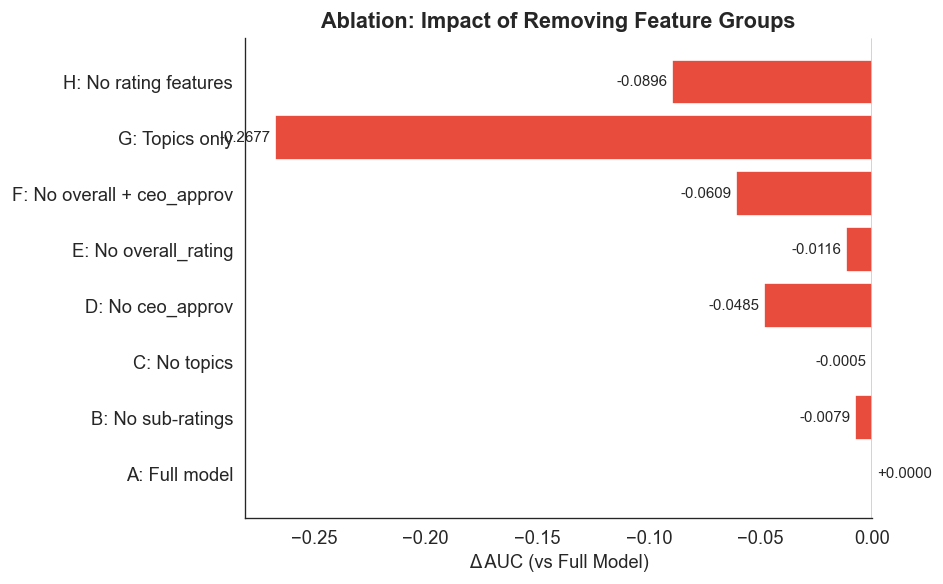

                    Config  N Features  Mean CV AUC  Std CV AUC   Δ AUC
             A: Full model         141       0.9080      0.0010  0.0000
         B: No sub-ratings         136       0.9001      0.0011 -0.0079
              C: No topics          24       0.9075      0.0009 -0.0005
          D: No ceo_approv         138       0.8595      0.0014 -0.0485
      E: No overall_rating         140       0.8964      0.0010 -0.0116
F: No overall + ceo_approv         137       0.8471      0.0015 -0.0609
            G: Topics only         117       0.6403      0.0014 -0.2677
     H: No rating features         135       0.8184      0.0018 -0.0896


In [35]:
# --- Figure: Ablation impact ---
fig, ax = plt.subplots(figsize=(8, 5))

# Color: grey for baseline, red for negative delta
colors = ['#95a5a6' if d == 0 else '#e74c3c' for d in abl_df['Δ AUC']]

ax.barh(abl_df['Config'], abl_df['Δ AUC'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Δ AUC (vs Full Model)')
ax.set_title('Ablation: Impact of Removing Feature Groups')

# Annotate values
for i, (config, delta) in enumerate(zip(abl_df['Config'], abl_df['Δ AUC'])):
    offset = 0.002 if delta >= 0 else -0.002
    ha = 'left' if delta >= 0 else 'right'
    ax.text(delta + offset, i, f'{delta:+.4f}', va='center', ha=ha, fontsize=9)

plt.tight_layout()
save_fig('ablation_impact')
plt.show()

# Print full table for reference
print(abl_df.round(4).to_string(index=False))

CEO approval and overall rating drive most of the model's predictive power (removing both costs 6pp AUC). Topic features add essentially nothing (−0.0005 AUC). However, their value is diagnostic rather than predictive: sub-ratings indicate which area needs attention (e.g., "culture & values is low"), but topics reveal what specifically employees discuss (e.g., "micromanagement", "lack of transparency"), enabling more targeted interventions.

## 6.10 Test Set Evaluation 

In [37]:
# --- 10. Test Set Evaluation ---
y_pred = lr_final.predict(X_test_df)
y_prob = lr_final.predict_proba(X_test_df)[:, 1]

print('TEST SET PERFORMANCE — Logistic Regression')
print('=' * 50)
print(f"  Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred):.4f}")
print(f"  AUC:       {roc_auc_score(y_test, y_prob):.4f}")

print('\nCV vs Test:')
print(f"  CV AUC:   {lr_cv_scores['test_auc'].mean():.4f}")
print(f"  Test AUC: {roc_auc_score(y_test, y_prob):.4f}")

TEST SET PERFORMANCE — Logistic Regression
  Accuracy:  0.8189
  Precision: 0.8741
  Recall:    0.8179
  F1:        0.8451
  AUC:       0.9074

CV vs Test:
  CV AUC:   0.9080
  Test AUC: 0.9074


Test AUC (0.907) matches CV AUC (0.908) closely, confirming the model generalises well to unseen data.

Saved: test_performance_final_v2.png


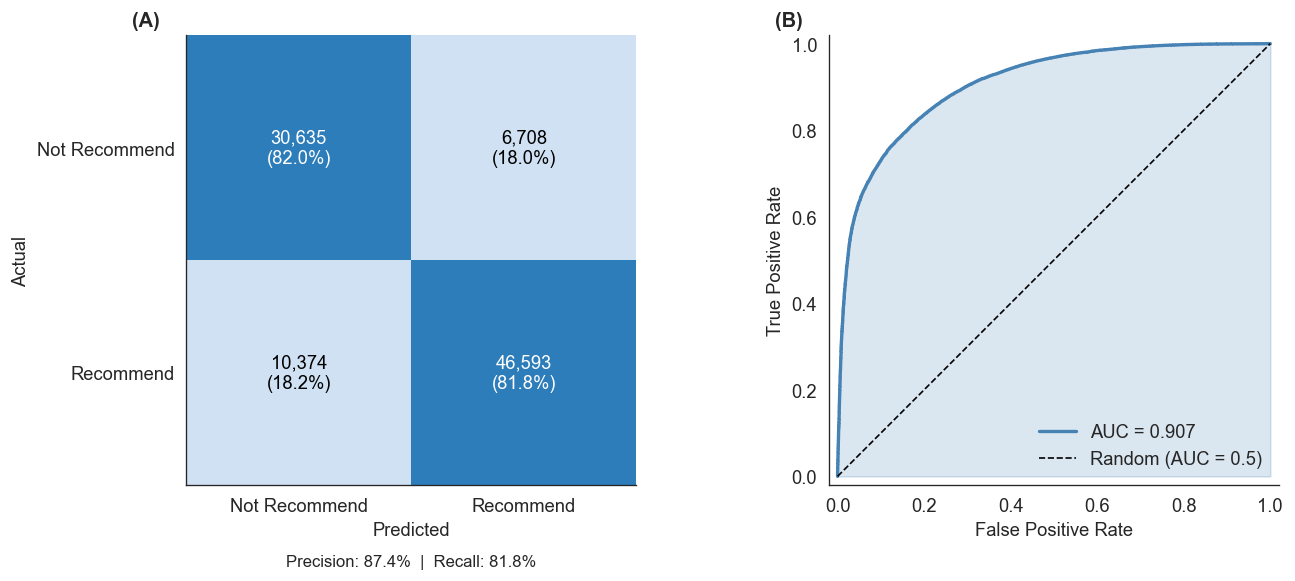

In [ ]:
# --- Confusion Matrix & ROC Curve ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Panel A: Confusion Matrix ---
ax = axes[0]

# Custom colors: correct predictions (diagonal) darker, errors lighter
colors = np.array([
    [0.7, 0.2],  # TN correct (dark), FP error (light)
    [0.2, 0.7]   # FN error (light), TP correct (dark)
])
im = ax.imshow(colors, cmap='Blues', vmin=0, vmax=1)

# Add counts and percentages
text_colors = [['white', 'black'], ['black', 'white']]
for i in range(2):
    for j in range(2):
        count = cm[i, j]
        pct = cm_pct[i, j]
        ax.text(j, i, f'{count:,}\n({pct:.1f}%)', 
                ha='center', va='center', fontsize=11,
                color=text_colors[i][j])

ax.set_xticks([0, 1])
ax.set_xticklabels(['Not Recommend', 'Recommend'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Not Recommend', 'Recommend'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

# Metrics below
ax.text(0.5, -0.18, f'Precision: {precision:.1%}  |  Recall: {recall:.1%}', 
        ha='center', transform=ax.transAxes, fontsize=10)

ax.text(-0.12, 1.02, '(A)', transform=ax.transAxes, fontsize=12, fontweight='bold')

# --- Panel B: ROC Curve ---
ax = axes[1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

# Fill area under curve
ax.fill_between(fpr, tpr, alpha=0.2, color='steelblue')
ax.plot(fpr, tpr, color='steelblue', linewidth=2, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')

# Diagonal reference line
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect('equal')  # Square aspect ratio (convention for ROC)

# Legend 
ax.legend(loc='lower right', frameon=False)

ax.text(-0.12, 1.02, '(B)', transform=ax.transAxes, fontsize=12, fontweight='bold')

plt.tight_layout()
save_fig('test_performance_final')
plt.show()

In [88]:
# Calculate pseudo-R²
ll_model = -log_loss(y_test, y_prob, normalize=False)
base_rate = y_test.mean()
y_null = np.full(len(y_test), base_rate)
ll_null = -log_loss(y_test, y_null, normalize=False)

print(f"\nLog-likelihood (model): {ll_model:.2f}")
print(f"Log-likelihood (null): {ll_null:.2f}")

mcfadden_r2 = 1 - (ll_model / ll_null)
print(f"McFadden's pseudo-R²: {mcfadden_r2:.3f}")


Log-likelihood (model): -36381.63
Log-likelihood (null): -63314.04
McFadden's pseudo-R²: 0.425


## 6.11 Error Analysis

Examine model reliability across confidence levels and identify failure modes.

In [53]:
# --- 11.1 Error Analysis ---

# Error by confidence (using |prob - 0.5| as confidence measure)
confidence = np.abs(y_prob - 0.5)
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
bin_labels = ['Very low', 'Low', 'Medium', 'High', 'Very high']
conf_bins = pd.cut(confidence, bins=bins, labels=bin_labels)

error_summary = pd.DataFrame({
    'confidence': conf_bins,
    'error': (y_pred != y_test)
}).groupby('confidence', observed=True).agg(
    n_samples=('error', 'count'),
    error_rate=('error', 'mean')
).reset_index()

# Error by overall rating
rating_error = pd.DataFrame({
    'overall_rating': X_test_df['overall_rating'],
    'error': (y_pred != y_test)
}).groupby('overall_rating').agg(
    n_samples=('error', 'count'),
    error_rate=('error', 'mean')
).reset_index()

display(error_summary)
display(rating_error)


,confidence,n_samples,error_rate
0,Very low,10479,0.473614
1,Low,11746,0.383450
2,Medium,13697,0.264145
3,High,17988,0.132533
4,Very high,40400,0.039926


,overall_rating,n_samples,error_rate
0,1.0,7356,0.027732
1,2.0,8555,0.074342
2,3.0,21477,0.325977
3,4.0,30783,0.196635
4,5.0,26139,0.121963


Saved: error_analysis_v5.png


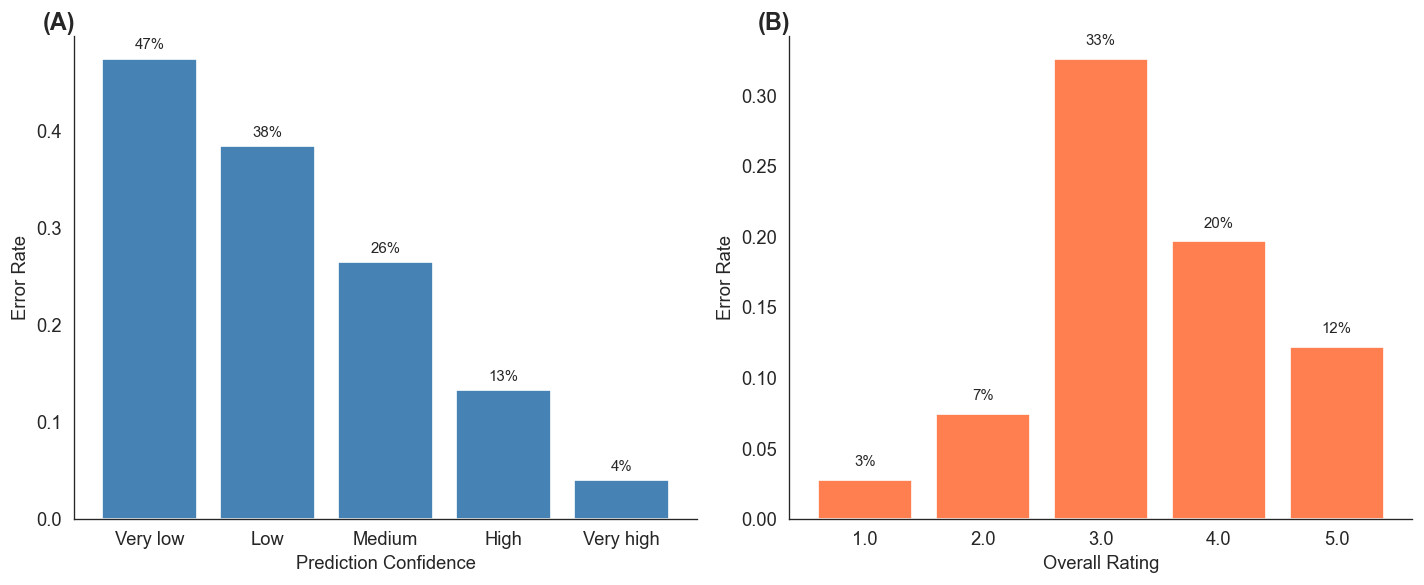

In [75]:
# --- Figure: Error Analysis ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Error by confidence
axes[0].bar(error_summary['confidence'], error_summary['error_rate'], color='steelblue')
axes[0].set_xlabel('Prediction Confidence')
axes[0].set_ylabel('Error Rate')
axes[0].text(-0.05, 1.05, '(A)', transform=axes[0].transAxes, 
             fontsize=14, fontweight='bold', va='top')
for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 0.01,
                 f'{height:.0%}', ha='center', fontsize=9)

# Panel 2: Error by overall rating
axes[1].bar(rating_error['overall_rating'].astype(str), rating_error['error_rate'], color='coral')
axes[1].set_xlabel('Overall Rating')
axes[1].set_ylabel('Error Rate')
axes[1].text(-0.05, 1.05, '(B)', transform=axes[1].transAxes, 
             fontsize=14, fontweight='bold', va='top')
for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.01,
                 f'{height:.0%}', ha='center', fontsize=9)
    
plt.tight_layout()
save_fig('error_analysis')
plt.show()

High-confidence predictions have ~4% error, while low-confidence predictions approach random chance (~47%). Neutral reviews (rating 3) drive most errors at 33% — inherently ambiguous cases. Extreme ratings are most predictive, with 1-star reviews showing lower error (3%) than 5-star (12%); negative sentiment appears more decisive.

In [50]:
# --- 11.2 High-Confidence Misclassifications ---
test_errors = df_test.copy()
test_errors['y_true'] = y_test
test_errors['y_pred'] = y_pred
test_errors['y_prob'] = y_prob
test_errors['correct'] = (test_errors['y_true'] == test_errors['y_pred'])
test_errors['confidence'] = np.abs(test_errors['y_prob'] - 0.5)

# False Positives: predicted Recommend, actually Not Recommend
fp_mask = (~test_errors['correct']) & (test_errors['y_pred'] == 1)
top_fp = test_errors[fp_mask].nlargest(5, 'confidence')

print('=== Top 5 High-Confidence FALSE POSITIVES ===')
print('(Predicted Recommend, actually Not Recommend)\n')
for _, row in top_fp.iterrows():
    print(f"Prob: {row['y_prob']:.3f} | Rating: {row['overall_rating']:.0f} | Current: {row['is_current']}")
    print(f"Pros: {str(row['pros'])[:100]}...")
    print(f"Cons: {str(row['cons'])[:100]}...")
    print()

# False Negatives: predicted Not Recommend, actually Recommend
fn_mask = (~test_errors['correct']) & (test_errors['y_pred'] == 0)
top_fn = test_errors[fn_mask].nlargest(5, 'confidence')

print('=== Top 5 High-Confidence FALSE NEGATIVES ===')
print('(Predicted Not Recommend, actually Recommend)\n')
for _, row in top_fn.iterrows():
    print(f"Prob: {row['y_prob']:.3f} | Rating: {row['overall_rating']:.0f} | Current: {row['is_current']}")
    print(f"Pros: {str(row['pros'])[:100]}...")
    print(f"Cons: {str(row['cons'])[:100]}...")
    print()

=== Top 5 High-Confidence FALSE POSITIVES ===
(Predicted Recommend, actually Not Recommend)

Prob: 0.988 | Rating: 5 | Current: 1
Pros: Great work culture, Trainings and Learning, Creativity and Innovation, Management Consulting, Effect...
Cons: Long hours/days but subject to how you can leverage your schedule to make it work for your work-life...

Prob: 0.988 | Rating: 5 | Current: 1
Pros: Good compensation and environment, good projects and great visibility...
Cons: No really, sometimes the projects got really tight deadlines...

Prob: 0.986 | Rating: 5 | Current: 0
Pros: I love working in the apple company and it is really great in the apple company I love it there it's...
Cons: I did not have any problems in the apple company and I loved it there but sometimes I am too lazy to...

Prob: 0.986 | Rating: 5 | Current: 1
Pros: Compensation not at par with the competitors...
Cons: Flexible work options , internal movements possible...

Prob: 0.986 | Rating: 5 | Current: 1
Pros: Good co-

High-confidence errors often show apparent inconsistencies between ratings, text, and labels — for example, 5-star reviews marked "Not Recommend." This may indicate label noise, though alternative explanations exist (e.g., "recommend" capturing a different construct than satisfaction). A subset of errors appears irreducible given data quality.

## 6.12 Calibration

Does the model's predicted probability actually match empirical frequency? Logistic Regression is generally well-calibrated, but worth verifying given class imbalance.


Saved: eval_calibration_curve_v1.png


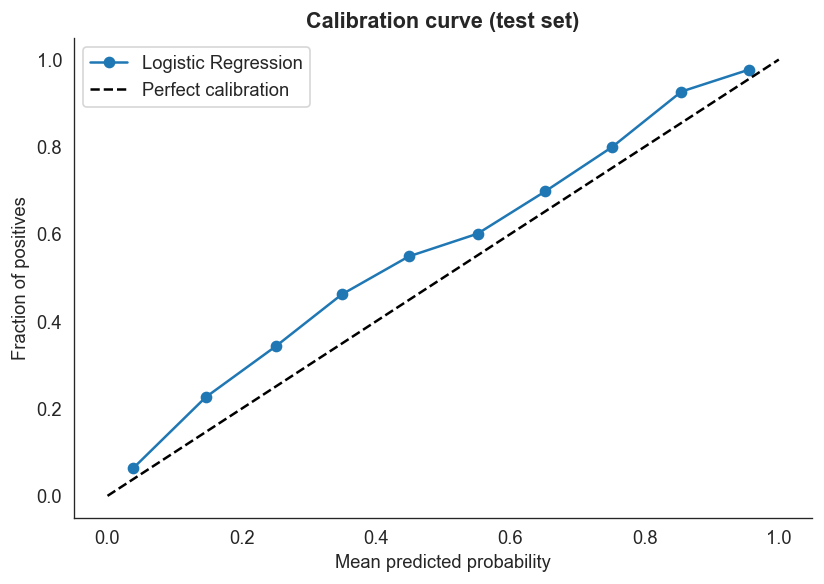

Expected Calibration Error (ECE): 0.0522


In [93]:
# Plot calibration curve

fig, ax = plt.subplots(figsize=(7, 5))
fraction_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy='uniform')
ax.plot(mean_pred, fraction_pos, marker='o', label='Logistic Regression')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration curve (test set)')
ax.legend()
plt.tight_layout()
save_fig('eval_calibration_curve')
plt.show()

# ECE — scalar summary of calibration quality
bins = np.linspace(0, 1, 11)
ece = 0.0
for i in range(len(bins) - 1):
    mask = (y_prob >= bins[i]) & (y_prob < bins[i+1])
    if mask.sum() > 0:
        ece += mask.sum() / len(y_test) * abs(y_test[mask].mean() - y_prob[mask].mean())
print(f"Expected Calibration Error (ECE): {ece:.4f}")

The model shows mild underconfidence — predicted probabilities are slightly compressed toward 0.5, consistent with L2 regularisation shrinking the decision boundary. 
ECE = 0.052 confirms overall good calibration: predicted probabilities reliably reflect true positive rates across the full range. 


## 6.13 Feature Importance

Address the core research question: what drives employee recommendations?

In [42]:
# --- 11.2 Feature Importance: LR Coefficients ---
lr_clf = lr_final.named_steps['clf']
coefs = lr_clf.coef_[0]

# Get feature names after preprocessing
coef_df = pd.DataFrame({
    'feature': scaled_feature_names,
    'coef': coefs,
    'abs_coef': np.abs(coefs)
}).sort_values('abs_coef', ascending=False)

print('Top 15 Features by |Coefficient|')
print('=' * 50)
print(coef_df.head(15).to_string(index=False))

Top 15 Features by |Coefficient|
                   feature      coef  abs_coef
     ceo_approv_No Opinion -2.613266  2.613266
     ceo_approv_Disapprove -1.523823  1.523823
            overall_rating  1.085687  1.085687
           ceo_approv_Mild -0.631416  0.631416
          review_year_2015  0.602031  0.602031
          review_year_2016  0.483174  0.483174
            culture_values  0.382428  0.382428
          review_year_2021 -0.330627  0.330627
          review_year_2013  0.298248  0.298248
                career_opp  0.267993  0.267993
   seniority_level_Unknown -0.263031  0.263031
               senior_mgmt  0.247615  0.247615
          review_year_2014  0.204838  0.204838
          review_year_2019 -0.188332  0.188332
seniority_level_Management  0.175508  0.175508


Saved: feature_importance_clean_v5.png


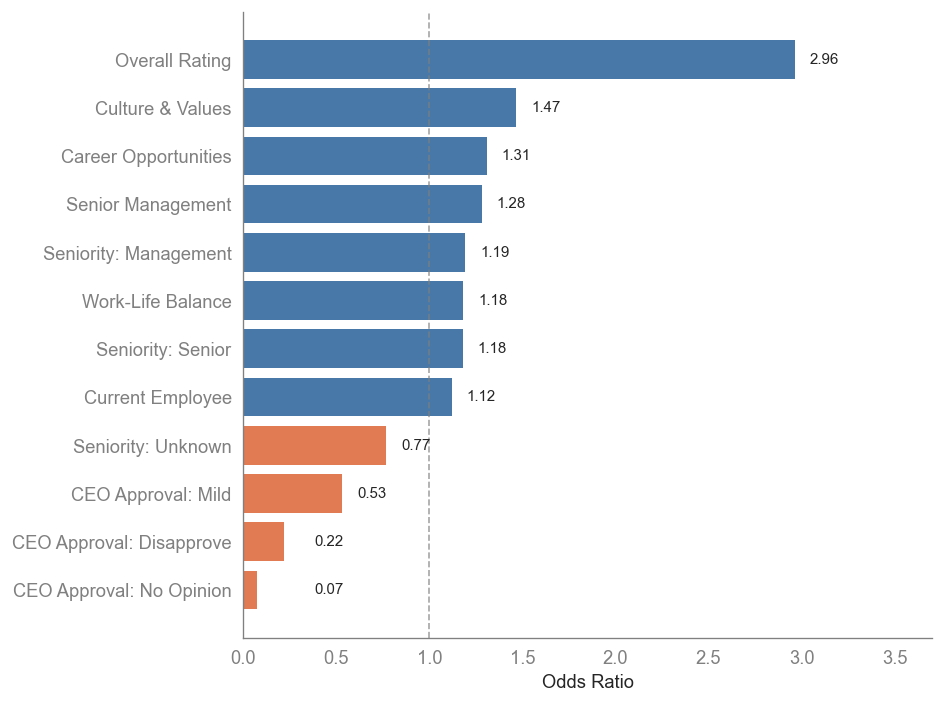

In [94]:
# --- Figure: Feature Importance (Odds Ratios) ---

# Filter out year dummies, topics, and other noise
exclude_patterns = ['review_year', 'intercept', 'pros_', 'cons_', 'firm_encoded']
substantive = coef_df[~coef_df['feature'].str.contains('|'.join(exclude_patterns), case=False)].copy()

# Calculate odds ratios
substantive['odds_ratio'] = np.exp(substantive['coef'])

# Sort by absolute coefficient magnitude and take top 12
substantive = substantive.nlargest(12, 'abs_coef')

# Clean feature names
label_map = {
    'overall_rating': 'Overall Rating',
    'culture_values': 'Culture & Values',
    'career_opp': 'Career Opportunities',
    'senior_mgmt': 'Senior Management',
    'work_life_balance': 'Work-Life Balance',
    'comp_benefits': 'Compensation & Benefits',
    'ceo_approv_No Opinion': 'CEO Approval: No Opinion',
    'ceo_approv_Disapprove': 'CEO Approval: Disapprove',
    'ceo_approv_Mild': 'CEO Approval: Mild',
    'seniority_level_Management': 'Seniority: Management',
    'seniority_level_Senior': 'Seniority: Senior',
    'seniority_level_Unknown': 'Seniority: Unknown',
    'seniority_level_Other': 'Seniority: Other',
    'is_current': 'Current Employee',
}
substantive['label'] = substantive['feature'].map(label_map).fillna(substantive['feature'])

# Sort by odds ratio (smallest at bottom, largest at top)
substantive = substantive.sort_values('odds_ratio', ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

# Slightly muted colors
colors = ['#4878A8' if x > 1 else '#E07B54' for x in substantive['odds_ratio']]
bars = ax.barh(substantive['label'], substantive['odds_ratio'], color=colors, edgecolor='none')

# Reference line at OR = 1 — grey and dashed
ax.axvline(x=1, color='grey', linestyle='--', linewidth=1, alpha=0.7)

# Add odds ratio labels
for bar, or_val in zip(bars, substantive['odds_ratio']):
    ax.text(max(or_val, 0.3) + 0.08, bar.get_y() + bar.get_height()/2, 
            f'{or_val:.2f}', ha='left', va='center', fontsize=9)

ax.set_xlabel('Odds Ratio')
ax.set_xlim(0, max(substantive['odds_ratio']) * 1.25)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Optional: lighten remaining spines
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

plt.tight_layout()
save_fig('feature_importance_clean')
plt.show()

In [58]:
# --- Odds Ratios (Top 10, excluding controls) ---
controls = ['review_year', 'firm_encoded']  # Add any other controls
top_features = coef_df[~coef_df['feature'].str.contains('|'.join(controls))].head(10).copy()
top_features['Odds Ratio'] = np.exp(top_features['coef'])
top_features['Interpretation'] = top_features['Odds Ratio'].apply(
    lambda x: f"{x:.2f}× more likely" if x > 1 else f"{1/x:.2f}× less likely"
)

print('Top 10 Predictors (excluding controls)')
print('=' * 70)
print(top_features[['feature', 'coef', 'Odds Ratio', 'Interpretation']].to_string(index=False))

Top 10 Predictors (excluding controls)
                   feature      coef  Odds Ratio     Interpretation
     ceo_approv_No Opinion -2.613266    0.073295 13.64× less likely
     ceo_approv_Disapprove -1.523823    0.217877  4.59× less likely
            overall_rating  1.085687    2.961473  2.96× more likely
           ceo_approv_Mild -0.631416    0.531838  1.88× less likely
            culture_values  0.382428    1.465839  1.47× more likely
                career_opp  0.267993    1.307338  1.31× more likely
   seniority_level_Unknown -0.263031    0.768718  1.30× less likely
               senior_mgmt  0.247615    1.280967  1.28× more likely
seniority_level_Management  0.175508    1.191852  1.19× more likely
         work_life_balance  0.166756    1.181466  1.18× more likely


CEO approval is the strongest predictor: relative to "Approve" (reference), "No Opinion," "Disapprove", and even "Mild" approval all reduce recommendation likelihood. Among sub-ratings, culture & values and career opportunities have the largest positive effects — actionable levers for employers. No topic features appear in the top 10, consistent with ablation findings.